In [ ]:
!pip install youtube-comment-downloader Sastrawi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 11.2 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import re
import string
from youtube_comment_downloader import YoutubeCommentDownloader, SORT_BY_RECENT

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
downloader = YoutubeCommentDownloader()

urls = {
    'Samsung': 'https://www.youtube.com/watch?v=ZGbp60qeIUM',
    'iPhone': 'https://www.youtube.com/watch?v=9-poYwCZxDQ&t=49s'
}

def scrape_data(url, brand, limit=1500):
    comments = downloader.get_comments_from_url(url, sort_by=SORT_BY_RECENT)
    data = []
    for i, comment in enumerate(comments):
        if i >= limit:
            break
        data.append({
            'text_raw': comment['text'],
            'brand': brand
        })
    return pd.DataFrame(data)

df = pd.concat([
    scrape_data(urls['Samsung'], 'Samsung'),
    scrape_data(urls['iPhone'], 'iPhone')
], ignore_index=True)

df.head()

,text_raw,brand
0,Infinix GT 50 Pro 5G nya kapan bang?,Samsung
1,Hp idaman para Gen Z,Samsung
2,"Pelit bgt samsung ngasi update, mending ke mid...",Samsung
3,Nonton ini pake samsung A54😍,Samsung
4,JD mending beli A56 aja yaa,Samsung


In [ ]:
stemmer = StemmerFactory().create_stemmer()
stopword = StopWordRemoverFactory().create_stop_word_remover()

def preprocess(text):
    text = text.lower()
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'\d+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = stopword.remove(text)
    text = stemmer.stem(text)
    return text.strip()

df['clean_text'] = df['text_raw'].apply(preprocess)

df.head()

,text_raw,brand,clean_text
0,Infinix GT 50 Pro 5G nya kapan bang?,Samsung,infinix gt pro g nya kapan bang
1,Hp idaman para Gen Z,Samsung,hp idam gen z
2,"Pelit bgt samsung ngasi update, mending ke mid...",Samsung,pelit bgt samsung ngasi update mending midrage...
3,Nonton ini pake samsung A54😍,Samsung,nonton pake samsung a
4,JD mending beli A56 aja yaa,Samsung,jd mending beli a aja yaa


In [ ]:
pos_words = ['bagus','keren','mantap','suka','love']
neg_words = ['jelek','buruk','mahal','lag','benci']

def label_sentiment(text):
    score = 0
    for w in pos_words:
        if w in text:
            score += 1
    for w in neg_words:
        if w in text:
            score -= 1
    if score > 0:
        return 'positif'
    elif score < 0:
        return 'negatif'
    else:
        return 'netral'

df['sentiment'] = df['clean_text'].apply(label_sentiment)

df['sentiment'].value_counts()

,count
sentiment,
netral,2657
positif,232
negatif,111


In [ ]:
vectorizer = TfidfVectorizer(max_features=1500)
X = vectorizer.fit_transform(df['clean_text'])
y = df['sentiment']

In [ ]:
X_train, X_test, y_train, y_test, brand_train, brand_test = train_test_split(
    X, y, df['brand'], test_size=0.2, random_state=42
)

In [ ]:
nb = MultinomialNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

In [ ]:
print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))
print(classification_report(y_test, y_pred_nb))

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

Naive Bayes Accuracy: 0.9066666666666666
              precision    recall  f1-score   support

     negatif       0.00      0.00      0.00        20
      netral       0.91      1.00      0.95       541
     positif       1.00      0.08      0.14        39

    accuracy                           0.91       600
   macro avg       0.64      0.36      0.36       600
weighted avg       0.88      0.91      0.87       600

KNN Accuracy: 0.9066666666666666
              precision    recall  f1-score   support

     negatif       0.00      0.00      0.00        20
      netral       0.91      1.00      0.95       541
     positif       1.00      0.08      0.14        39

    accuracy                           0.91       600
   macro avg       0.64      0.36      0.36       600
weighted avg       0.88      0.91      0.87       600



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

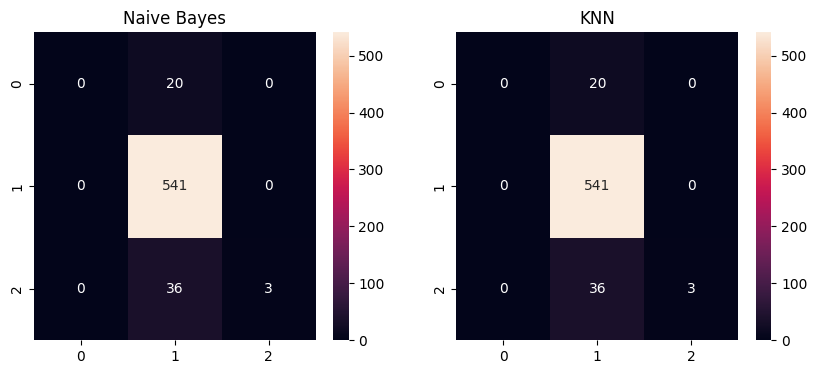

In [ ]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
sns.heatmap(confusion_matrix(y_test, y_pred_nb), annot=True, fmt='d')
plt.title("Naive Bayes")

plt.subplot(1,2,2)
sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d')
plt.title("KNN")

plt.show()

In [ ]:
df_result = pd.DataFrame({
    'brand': brand_test,
    'actual': y_test,
    'nb_pred': y_pred_nb,
    'knn_pred': y_pred_knn
})

df_result.groupby('brand')['actual'].value_counts()

brand    actual 
Samsung  netral     277
         positif     22
         negatif     14
iPhone   netral     264
         positif     17
         negatif      6
Name: count, dtype: int64

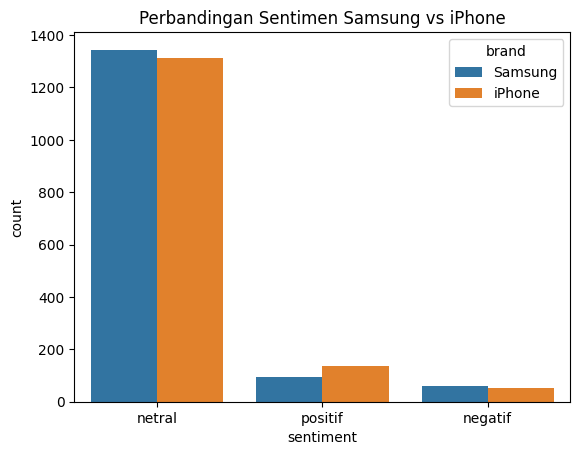

In [ ]:
sns.countplot(data=df, x='sentiment', hue='brand')
plt.title("Perbandingan Sentimen Samsung vs iPhone")
plt.show()

In [ ]:
!pip install statsmodels

from statsmodels.stats.contingency_tables import mcnemar
import numpy as np

# Reset index biar aman
y_test_reset = y_test.reset_index(drop=True)

b = 0
c = 0

for i in range(len(y_test_reset)):
    if (y_pred_nb[i] == y_test_reset[i]) and (y_pred_knn[i] != y_test_reset[i]):
        b += 1
    elif (y_pred_nb[i] != y_test_reset[i]) and (y_pred_knn[i] == y_test_reset[i]):
        c += 1

table = [[0, b],
         [c, 0]]

print("Tabel McNemar:")
print(np.array(table))

result = mcnemar(table, exact=True)

print("\nHasil McNemar Test")
print("Statistic:", result.statistic)
print("p-value:", result.pvalue)

alpha = 0.05
if result.pvalue > alpha:
    print("Kesimpulan: Tidak ada perbedaan signifikan antara Naive Bayes dan KNN")
else:
    print("Kesimpulan: Ada perbedaan signifikan antara Naive Bayes dan KNN")

Tabel McNemar:
[[0 2]
 [2 0]]

Hasil McNemar Test
Statistic: 2.0
p-value: 1.0
Kesimpulan: Tidak ada perbedaan signifikan antara Naive Bayes dan KNN


In [ ]:
from collections import Counter

df_pos = df[df['sentiment'] == 'positif']
df_neg = df[df['sentiment'] == 'negatif']

text_pos = " ".join(df_pos['clean_text'])
text_neg = " ".join(df_neg['clean_text'])

words_pos = text_pos.split()
words_neg = text_neg.split()

counter_pos = Counter(words_pos)
counter_neg = Counter(words_neg)

top_pos = counter_pos.most_common(10)
top_neg = counter_neg.most_common(10)

print("Top 10 Kata POSITIF:")
for word, freq in top_pos:
    print(f"{word} : {freq}")

print("\nTop 10 Kata NEGATIF:")
for word, freq in top_neg:
    print(f"{word} : {freq}")

Top 10 Kata POSITIF:
bagus : 142
yg : 91
a : 79
samsung : 75
pro : 74
suka : 61
lebih : 59
iphone : 56
nya : 51
hp : 50

Top 10 Kata NEGATIF:
mahal : 58
hp : 40
yg : 38
samsung : 34
a : 32
aja : 27
nya : 26
harga : 24
flagship : 23
beli : 21


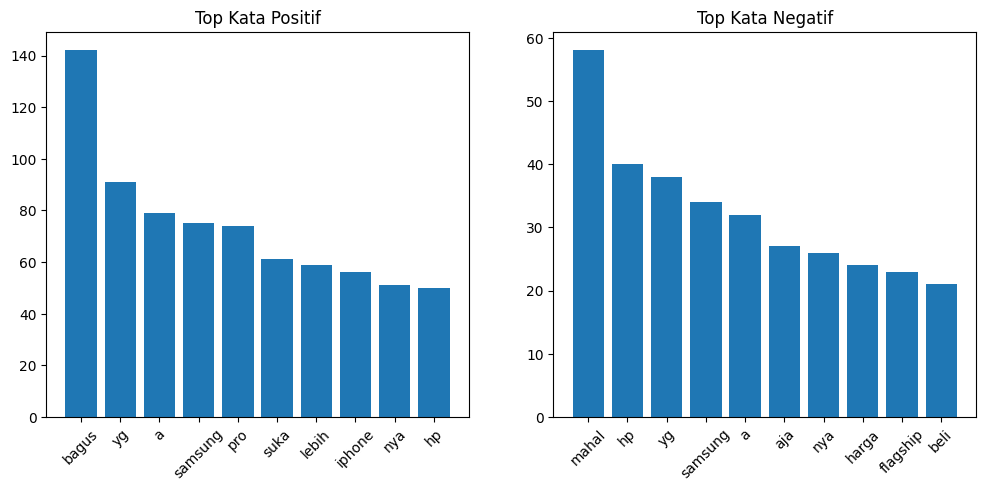

In [ ]:
import matplotlib.pyplot as plt

words_p, freq_p = zip(*top_pos)
words_n, freq_n = zip(*top_neg)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.bar(words_p, freq_p)
plt.title("Top Kata Positif")
plt.xticks(rotation=45)

plt.subplot(1,2,2)
plt.bar(words_n, freq_n)
plt.title("Top Kata Negatif")
plt.xticks(rotation=45)

plt.show()

In [ ]:
from collections import Counter

# Samsung
df_sam_pos = df[(df['brand'] == 'Samsung') & (df['sentiment'] == 'positif')]
df_sam_neg = df[(df['brand'] == 'Samsung') & (df['sentiment'] == 'negatif')]

# iPhone
df_iph_pos = df[(df['brand'] == 'iPhone') & (df['sentiment'] == 'positif')]
df_iph_neg = df[(df['brand'] == 'iPhone') & (df['sentiment'] == 'negatif')]

def get_top_words(data, n=10):
    text = " ".join(data['clean_text'])
    words = text.split()
    return Counter(words).most_common(n)

print("Samsung Positif:", get_top_words(df_sam_pos))
print("Samsung Negatif:", get_top_words(df_sam_neg))

print("\niPhone Positif:", get_top_words(df_iph_pos))
print("iPhone Negatif:", get_top_words(df_iph_neg))

Samsung Positif: [('a', 78), ('samsung', 75), ('bagus', 64), ('yg', 40), ('hp', 38), ('beli', 27), ('lebih', 26), ('aja', 25), ('nya', 25), ('suka', 22)]
Samsung Negatif: [('mahal', 35), ('samsung', 32), ('a', 32), ('hp', 25), ('yg', 20), ('harga', 18), ('nya', 18), ('udh', 13), ('flagship', 13), ('aja', 12)]

iPhone Positif: [('bagus', 78), ('pro', 71), ('iphone', 54), ('yg', 51), ('suka', 39), ('warna', 35), ('lebih', 33), ('kamera', 30), ('nya', 26), ('keren', 19)]
iPhone Negatif: [('mahal', 23), ('yg', 18), ('iphone', 17), ('hp', 15), ('aja', 15), ('udah', 11), ('beli', 10), ('flagship', 10), ('pro', 9), ('nya', 8)]


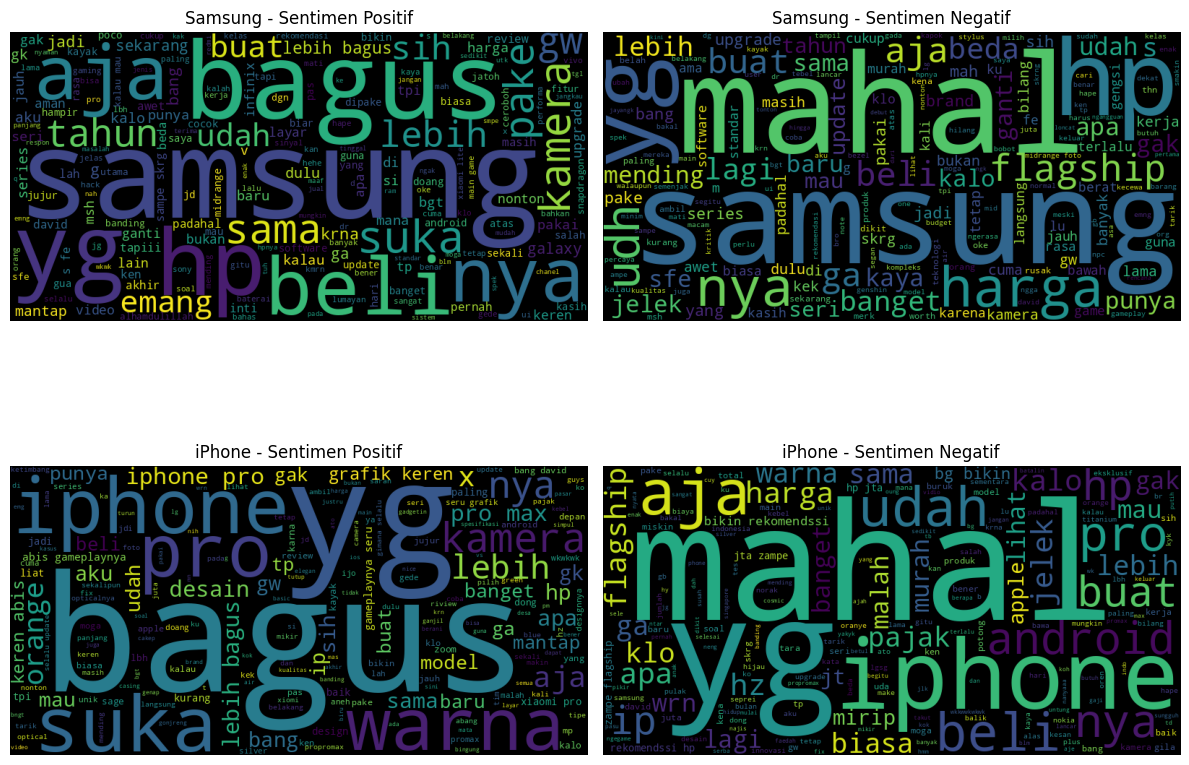

In [ ]:
!pip install wordcloud

from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Fungsi membuat wordcloud
def generate_wordcloud(data, title):
    text = " ".join(data['clean_text'])

    if len(text.strip()) == 0:
        print(f"Tidak ada data untuk {title}")
        return

    wc = WordCloud(width=800, height=400).generate(text)

    plt.imshow(wc)
    plt.title(title)
    plt.axis('off')

# Filter data
df_sam_pos = df[(df['brand'] == 'Samsung') & (df['sentiment'] == 'positif')]
df_sam_neg = df[(df['brand'] == 'Samsung') & (df['sentiment'] == 'negatif')]

df_iph_pos = df[(df['brand'] == 'iPhone') & (df['sentiment'] == 'positif')]
df_iph_neg = df[(df['brand'] == 'iPhone') & (df['sentiment'] == 'negatif')]

# Plot 4 WordCloud
plt.figure(figsize=(12,10))

plt.subplot(2,2,1)
generate_wordcloud(df_sam_pos, "Samsung - Sentimen Positif")

plt.subplot(2,2,2)
generate_wordcloud(df_sam_neg, "Samsung - Sentimen Negatif")

plt.subplot(2,2,3)
generate_wordcloud(df_iph_pos, "iPhone - Sentimen Positif")

plt.subplot(2,2,4)
generate_wordcloud(df_iph_neg, "iPhone - Sentimen Negatif")

plt.tight_layout()
plt.show()